# Model Comparison — Rossmann Store 1 Daily Sales

Fair, apples-to-apples comparison of four forecasting approaches against a seasonal-naive baseline, backtested across 6 rolling 42-day windows and scored with MAE, RMSE, MAPE, and WAPE:

- **Seasonal Naive** — baseline, season length 7
- **Prophet** — settings from `forecast_prophet.ipynb`, plus `Promo`/`SchoolHoliday`/`IsStateHoliday`/`Open` as regressors
- **XGBoost** — features/settings from `forecast_xgboost.ipynb`, plus the same four exogenous columns; forecasts built recursively so no test values leak into features
- **AutoARIMA** — `statsforecast`, season_length=7, same four exogenous columns via `X_df`
- **AutoETS** — `statsforecast`, season_length=7, no exogenous support (pure univariate)

**Key design choices:**

- **Full calendar, not just open days.** The series includes the ~161 days Store 1 is closed (mostly Sundays, plus state holidays), with `Sales == 0` by construction — so `lag_7` and `season_length=7` always mean a true calendar week.
- **Scoring is restricted to open days**, since MAPE/WAPE are undefined at 0 sales — the same convention Rossmann's own RMSPE metric uses.
- **MAPE is the headline metric** (matches Rossmann's framing), but it can be skewed by low-sales days like Christmas Eve/New Year's Eve (section 1). **WAPE** is reported alongside as a check, since a single low-sales day can't dominate it the way it can MAPE.
- **`Promo`, `SchoolHoliday`, `IsStateHoliday`, `Open`** feed every model that supports exogenous inputs — all four are known ahead of the forecast horizon in a real deployment.
- **Fit and forecast time are measured separately** per model/fold, since production would retrain nightly — training cost and forecast cost are different operational concerns, and both matter for the recommendation.

**Notebook structure:**

1. Data & exploratory analysis
2. Backtest setup — shared config and model-fitting functions
3. Run the backtest — fit and score all 5 models x 6 folds
4. Zoom in on the most recent fold
5. Results across all folds — the recommendation


In [ ]:
import random
import time
from typing import cast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from prophet import Prophet
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from statsforecast import StatsForecast
from statsforecast.models import AutoARIMA, AutoETS, SeasonalNaive
from xgboost import XGBRegressor

SEED = 42
random.seed(SEED)
np.random.seed(SEED)


## 1. Data & exploratory analysis

In [2]:
df = pd.read_csv('data/rossmann/train.csv', low_memory=False, parse_dates=['Date'])
store_df = df[df['Store'] == 1].sort_values('Date').reset_index(drop=True)
store_df['IsStateHoliday'] = (store_df['StateHoliday'] != '0').astype(int)

print(f"Rows: {len(store_df)} ({store_df['Open'].sum()} open, {(store_df['Open'] == 0).sum()} closed)")
print(f"Date range: {store_df['Date'].min().date()} to {store_df['Date'].max().date()}")
store_df[['Date', 'Open', 'Sales', 'Promo', 'SchoolHoliday', 'IsStateHoliday']].head()


Rows: 942 (781 open, 161 closed)
Date range: 2013-01-01 to 2015-07-31


,Date,Open,Sales,Promo,SchoolHoliday,IsStateHoliday
0,2013-01-01,0,0,0,1,1
1,2013-01-02,1,5530,0,1,0
2,2013-01-03,1,4327,0,1,0
3,2013-01-04,1,4486,0,1,0
4,2013-01-05,1,4997,0,1,0


**What to look for:** the orange 30-day rolling mean traces the overall trend above the noisy daily line; also watch for the weekly pattern (why every model here uses `season_length=7` / weekly lags) and any stretches that look hard to forecast (promotions, holidays).

In [ ]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(store_df['Date'], store_df['Sales'], linewidth=0.5, alpha=0.6, color='steelblue', label='Daily sales')
ax.plot(store_df['Date'], store_df['Sales'].rolling(30, min_periods=1).mean(), linewidth=1.8, color='darkorange', label='30-day rolling mean')
ax.set_title('Store 1 — Daily Sales (all calendar days; dips to 0 are closed days)')
ax.set_xlabel('Date')
ax.set_ylabel('Sales')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()


The series shows a mild upward trend, strong weekly repetition, and sharp spikes. The two tallest — 23 Dec 2013 and 22 Dec 2014 — are the pre-Christmas rush, not promos (`Promo == 0` both times); recurring every year, so it's seasonal, not a one-off. The next two plots zoom in to make the weekly pattern and the holiday cycle easier to read.

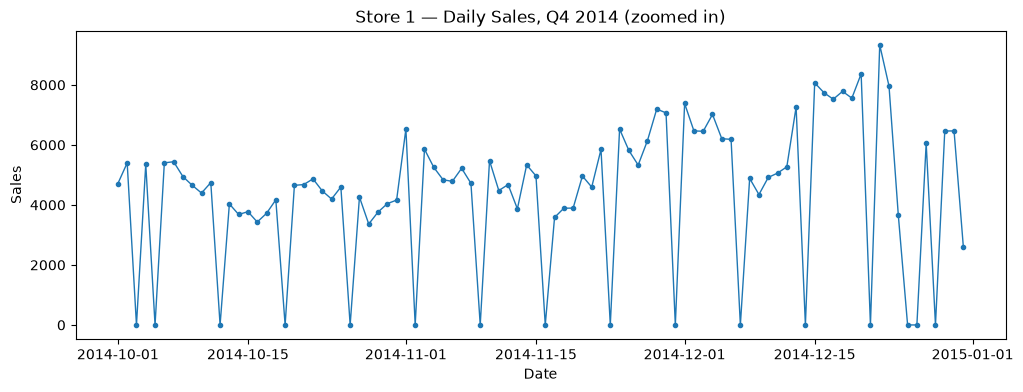

In [4]:
zoom = store_df[(store_df['Date'] >= '2014-10-01') & (store_df['Date'] < '2015-01-01')]

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(zoom['Date'], zoom['Sales'], marker='o', markersize=3, linewidth=1)
ax.set_title('Store 1 — Daily Sales, Q4 2014 (zoomed in)')
ax.set_xlabel('Date')
ax.set_ylabel('Sales')
plt.show()

Zoomed in, the weekly cycle (exact shape in the day-of-week breakdown below) is clear through October–November. December adds a second, larger pattern on top: sales build to a peak on 22 Dec, then crash on Christmas Eve (24 Dec) and crash harder on New Year's Eve (31 Dec, the series' lowest point) — brief rebounds in between show it's specifically each holiday's eve that's dead, not the whole week. The full-range view above only shows this as one spike; it's actually a two-week build-peak-crash cycle.

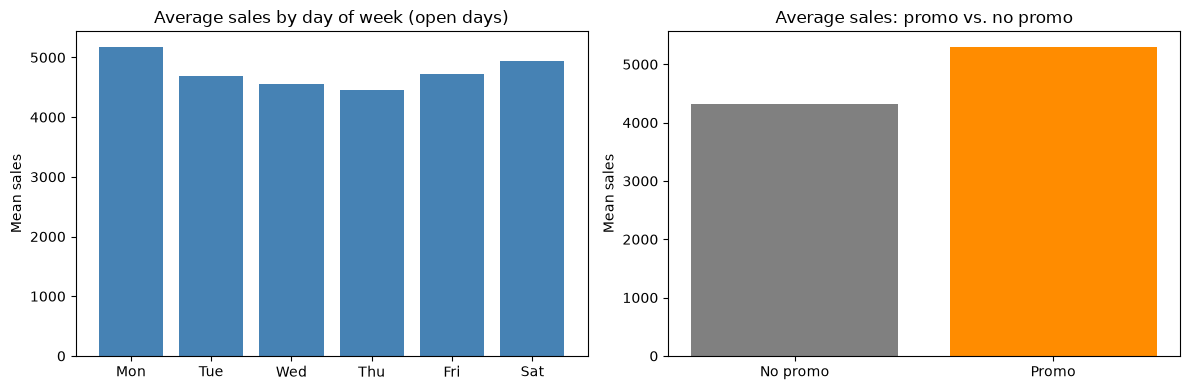

Promo days lift average sales by 22.7%


In [5]:
open_df = store_df[store_df['Open'] == 1]

day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
by_dow = open_df.groupby(open_df['Date'].dt.dayofweek)['Sales'].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar([day_names[d] for d in by_dow.index], by_dow.values, color='steelblue')
axes[0].set_title('Average sales by day of week (open days)')
axes[0].set_ylabel('Mean sales')

promo_means = open_df.groupby('Promo')['Sales'].mean()
axes[1].bar(['No promo', 'Promo'], promo_means.values, color=['gray', 'darkorange'])
axes[1].set_title('Average sales: promo vs. no promo')
axes[1].set_ylabel('Mean sales')

plt.tight_layout()
plt.show()

print(f"Promo days lift average sales by {(promo_means[1] / promo_means[0] - 1) * 100:.1f}%")


Sales peak on Monday, trough midweek (lowest Thursday), then recover through Friday–Saturday — not a simple taper. (Computed on open days only; Sunday is always closed — 0 sales — so it has no bar here, but is still a real row in the full calendar series used below.) Promo days lift average sales by about 23%. `Promo`, `SchoolHoliday`, and `IsStateHoliday` feed every regression-capable model below as known exogenous inputs.


## 2. Backtest setup

Scored with a **rolling-origin backtest**: 6 consecutive, non-overlapping 42-day windows, each ending progressively later. Each fold refits from scratch on an **expanding** training window — all data strictly before that fold's test window. No train set touches its own test dates; no two test windows overlap.

- **42-day horizon** matches the business horizon in the README (six weeks of staffing/stock planning) — not chosen for statistical convenience.
- **6 folds** (up from 4) leaves ~1.9 years of initial training history before fold 1 — enough margin for the yearly-seasonality models (Prophet, AutoETS), and a firmer read on consistency than 4 folds gave.
- **Evaluation is restricted to open days**: closed days have `Sales == 0` by construction, which makes MAPE/WAPE undefined there — the same convention Rossmann's own RMSPE metric uses.


In [6]:
HORIZON = 42
N_FOLDS = 6
EXOG_COLS = ['Open', 'Promo', 'SchoolHoliday', 'IsStateHoliday']  # known ahead of the forecast horizon, not derived from future sales

fold_starts = [len(store_df) - HORIZON * k for k in range(N_FOLDS, 0, -1)]
print(f"Fold test-window start row indices: {fold_starts}")


Fold test-window start row indices: [690, 732, 774, 816, 858, 900]


### Model-fitting functions

One function per model, each taking a fold's train/test split and returning a 42-step forecast. These are the **only** place model logic lives — the backtest loop in section 3 calls them once per fold, so there's no separate "single split" pass to keep in sync with the backtest.

Baseline uses `statsforecast`'s own `SeasonalNaive` rather than a hand-rolled tile, now that the series has a true contiguous daily frequency (the old open-days-only gaps made that inconsistent — no longer an issue). Mathematically identical to before: forecast day *h* = the actual value from 7 days earlier, repeated across the horizon.


In [7]:
def fold_seasonal_naive(train_fold, horizon):
    sf_tr = pd.DataFrame({'unique_id': 'store_1', 'ds': train_fold['Date'].values, 'y': train_fold['Sales'].values})
    sf_naive = StatsForecast(models=[SeasonalNaive(season_length=7)], freq='D', n_jobs=1)

    t0 = time.perf_counter()
    sf_naive.fit(df=sf_tr)
    fit_seconds = time.perf_counter() - t0

    t0 = time.perf_counter()
    fc = cast(pd.DataFrame, sf_naive.predict(h=horizon))
    predict_seconds = time.perf_counter() - t0

    return fc['SeasonalNaive'].values, fit_seconds, predict_seconds


Prophet is configured with both `weekly_seasonality=True` and `yearly_seasonality=True`, since section 1's EDA showed both a weekly cycle and a recurring yearly holiday pattern. The four exogenous columns are added as linear regressors via `add_regressor`, then fit on a fold's train rows. Unlike XGBoost, no recursive forecasting step is needed: Prophet predicts directly from the fold's real future calendar and regressor values, since its forecast at day *h* doesn't depend on its own prediction at day *h-1*.


In [8]:
def fold_prophet(train_fold, test_fold):
    df_p = train_fold[['Date', 'Sales'] + EXOG_COLS].rename(columns={'Date': 'ds', 'Sales': 'y'})
    m = Prophet(weekly_seasonality=True, yearly_seasonality=True)  # type: ignore[arg-type]
    for col in EXOG_COLS:
        m.add_regressor(col)

    t0 = time.perf_counter()
    m.fit(df_p)
    fit_seconds = time.perf_counter() - t0

    future = test_fold[['Date'] + EXOG_COLS].rename(columns={'Date': 'ds'})
    t0 = time.perf_counter()
    pred = m.predict(future)
    predict_seconds = time.perf_counter() - t0

    return pred['yhat'].values, fit_seconds, predict_seconds


XGBoost keeps the calendar/lag/rolling features from `forecast_xgboost.ipynb` (`year`, `month`, `dayofweek`, `quarter`, `sales_lag_1/2/3/7`, `sales_rolling_mean_7`, `sales_rolling_std_7`) plus the same four exogenous columns as Prophet. It trains only on a fold's train rows, and forecasts **recursively**: lag/rolling features at each step come from train history plus the model's own earlier predictions (never from the fold's actual test `Sales`), while exogenous columns come from the fold's real future calendar, since those are known ahead of time. No leakage either way.


In [9]:
feature_cols = ['year', 'month', 'dayofweek', 'quarter', 'sales_lag_1', 'sales_lag_2', 'sales_lag_3', 'sales_lag_7', 'sales_rolling_mean_7', 'sales_rolling_std_7'] + EXOG_COLS


def add_features(d):
    d = d.copy()
    d['year'] = d['Date'].dt.year
    d['month'] = d['Date'].dt.month
    d['dayofweek'] = d['Date'].dt.dayofweek
    d['quarter'] = d['Date'].dt.quarter
    d['sales_lag_1'] = d['Sales'].shift(1)
    d['sales_lag_2'] = d['Sales'].shift(2)
    d['sales_lag_3'] = d['Sales'].shift(3)
    d['sales_lag_7'] = d['Sales'].shift(7)
    d['sales_rolling_mean_7'] = d['Sales'].shift(1).rolling(7).mean()
    d['sales_rolling_std_7'] = d['Sales'].shift(1).rolling(7).std()
    return d


def fold_xgboost(train_fold, test_fold, horizon, seed):
    train_feat_fold = add_features(train_fold[['Date', 'Sales'] + EXOG_COLS]).dropna().reset_index(drop=True)
    X_tr = train_feat_fold[feature_cols]
    y_tr = train_feat_fold['Sales']

    model = XGBRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=seed,
    )
    t0 = time.perf_counter()
    model.fit(X_tr, y_tr)
    fit_seconds = time.perf_counter() - t0

    t0 = time.perf_counter()
    hist = train_feat_fold[['Date', 'Sales'] + EXOG_COLS].copy()
    preds = []
    for i in range(horizon):
        next_date = test_fold['Date'].iloc[i]
        recent = hist['Sales'].values
        row = {
            'year': next_date.year,
            'month': next_date.month,
            'dayofweek': next_date.dayofweek,
            'quarter': next_date.quarter,
            'sales_lag_1': recent[-1],
            'sales_lag_2': recent[-2],
            'sales_lag_3': recent[-3],
            'sales_lag_7': recent[-7],
            'sales_rolling_mean_7': recent[-7:].mean(),
            'sales_rolling_std_7': recent[-7:].std(ddof=1),
        }
        for col in EXOG_COLS:
            row[col] = test_fold[col].iloc[i]
        X_new = pd.DataFrame([row])[feature_cols]
        pred = model.predict(X_new)[0]
        preds.append(pred)
        new_row = {'Date': next_date, 'Sales': pred}
        for col in EXOG_COLS:
            new_row[col] = test_fold[col].iloc[i]
        hist = pd.concat([hist, pd.DataFrame([new_row])], ignore_index=True)
    predict_seconds = time.perf_counter() - t0
    return np.array(preds), fit_seconds, predict_seconds


The full-calendar series already has the regular daily frequency `statsforecast` needs — no synthetic placeholder dates required. AutoARIMA takes the same four exogenous columns as Prophet/XGBoost via `statsforecast`'s `X_df` interface (historical values to fit, the fold's real future values to forecast). AutoETS has no exogenous support in `statsforecast` — it stays a pure univariate model, and it's the one model here that can never see `Promo` or holidays coming.


In [10]:
def fold_statsforecast(train_fold, test_fold, horizon, exog_cols):
    sf_tr = pd.DataFrame({'unique_id': 'store_1', 'ds': train_fold['Date'].values, 'y': train_fold['Sales'].values})

    sf_ets = StatsForecast(models=[AutoETS(season_length=7)], freq='D', n_jobs=1)
    t0 = time.perf_counter()
    sf_ets.fit(df=sf_tr)
    ets_fit_seconds = time.perf_counter() - t0
    t0 = time.perf_counter()
    fc_ets = cast(pd.DataFrame, sf_ets.predict(h=horizon))
    ets_predict_seconds = time.perf_counter() - t0

    sf_tr_arima = sf_tr.copy()
    for col in exog_cols:
        sf_tr_arima[col] = train_fold[col].values
    futr_df = pd.DataFrame({'unique_id': 'store_1', 'ds': test_fold['Date'].values})
    for col in exog_cols:
        futr_df[col] = test_fold[col].values

    sf_arima = StatsForecast(models=[AutoARIMA(season_length=7)], freq='D', n_jobs=1)
    t0 = time.perf_counter()
    sf_arima.fit(df=sf_tr_arima)
    arima_fit_seconds = time.perf_counter() - t0
    t0 = time.perf_counter()
    fc_arima = cast(pd.DataFrame, sf_arima.predict(h=horizon, X_df=futr_df))
    arima_predict_seconds = time.perf_counter() - t0

    return (
        fc_arima['AutoARIMA'].values, arima_fit_seconds, arima_predict_seconds,
        fc_ets['AutoETS'].values, ets_fit_seconds, ets_predict_seconds,
    )


## 3. Run the backtest — fit and score every model, every fold

Every fold's forecasts are kept, not just its scores, so section 4 can zoom in without refitting. Fit time and forecast time are timed separately per model — relevant since production would retrain nightly, and the two are different operational costs.


In [11]:
per_fold_rows = []
fold_detail = {}  # fold_num -> {'test_df': ..., 'actual': ..., 'forecasts': {model: array}}

for fold_num, start in enumerate(fold_starts, start=1):
    train_fold = store_df.iloc[:start].reset_index(drop=True)
    test_fold = store_df.iloc[start:start + HORIZON].reset_index(drop=True)
    actual_fold = test_fold['Sales'].values
    open_mask = (test_fold['Open'] == 1).to_numpy(dtype=bool)

    naive_fc, naive_fit_seconds, naive_predict_seconds = fold_seasonal_naive(train_fold, HORIZON)
    prophet_fc, prophet_fit_seconds, prophet_predict_seconds = fold_prophet(train_fold, test_fold)
    xgb_fc, xgb_fit_seconds, xgb_predict_seconds = fold_xgboost(train_fold, test_fold, HORIZON, SEED)
    (
        autoarima_fc, arima_fit_seconds, arima_predict_seconds,
        autoets_fc, ets_fit_seconds, ets_predict_seconds,
    ) = fold_statsforecast(train_fold, test_fold, HORIZON, EXOG_COLS)

    fold_forecasts = {
        'Seasonal Naive': naive_fc,
        'Prophet': prophet_fc,
        'XGBoost': xgb_fc,
        'AutoARIMA': autoarima_fc,
        'AutoETS': autoets_fc,
    }
    fold_fit_seconds = {
        'Seasonal Naive': naive_fit_seconds,
        'Prophet': prophet_fit_seconds,
        'XGBoost': xgb_fit_seconds,
        'AutoARIMA': arima_fit_seconds,
        'AutoETS': ets_fit_seconds,
    }
    fold_predict_seconds = {
        'Seasonal Naive': naive_predict_seconds,
        'Prophet': prophet_predict_seconds,
        'XGBoost': xgb_predict_seconds,
        'AutoARIMA': arima_predict_seconds,
        'AutoETS': ets_predict_seconds,
    }

    fold_detail[fold_num] = {
        'test_df': test_fold,
        'actual': actual_fold,
        'forecasts': fold_forecasts,
    }

    # Score on open days only: closed-day sales are always 0, which makes MAPE/WAPE undefined there.
    actual_open = actual_fold[open_mask]
    actual_open_sum = actual_open.sum()
    naive_mape_fold = mean_absolute_percentage_error(actual_open, naive_fc[open_mask]) * 100

    for name, pred in fold_forecasts.items():
        pred_open = pred[open_mask]
        mae = mean_absolute_error(actual_open, pred_open)
        rmse = mean_squared_error(actual_open, pred_open) ** 0.5
        mape = mean_absolute_percentage_error(actual_open, pred_open) * 100
        # WAPE: total absolute error over total actual sales. Unlike MAPE, a single low-sales
        # day can't dominate it, since the division happens once over the fold, not per day.
        wape = np.abs(actual_open - pred_open).sum() / actual_open_sum * 100
        pct_change = (mape - naive_mape_fold) / naive_mape_fold * 100
        per_fold_rows.append({
            'fold': fold_num,
            'test_start': test_fold['Date'].iloc[0].date(),
            'test_end': test_fold['Date'].iloc[-1].date(),
            'model': name,
            'MAE': mae,
            'RMSE': rmse,
            'MAPE': mape,
            'WAPE': wape,
            '% change vs seasonal naive': pct_change,
            'fit_seconds': fold_fit_seconds[name],
            'predict_seconds': fold_predict_seconds[name],
        })

per_fold_df = pd.DataFrame(per_fold_rows)

print(f"\nBacktest complete — 5 models x {N_FOLDS} folds fit and scored (scored on open days only).")
print("Per-fold results (lower MAE/RMSE/MAPE/WAPE is better; negative % change means a model beat the baseline):\n")
print(per_fold_df.round(2).to_string(index=False))

22:44:50 - cmdstanpy - INFO - Chain [1] start processing


22:44:51 - cmdstanpy - INFO - Chain [1] done processing


22:46:58 - cmdstanpy - INFO - Chain [1] start processing


22:46:58 - cmdstanpy - INFO - Chain [1] done processing


22:48:48 - cmdstanpy - INFO - Chain [1] start processing


...

22:50:11 - cmdstanpy - INFO - Chain [1] start processing


22:50:11 - cmdstanpy - INFO - Chain [1] done processing


22:50:38 - cmdstanpy - INFO - Chain [1] start processing


22:50:38 - cmdstanpy - INFO - Chain [1] done processing



Backtest complete — 5 models x 6 folds fit and scored (scored on open days only).
Per-fold results (lower MAE/RMSE/MAPE/WAPE is better; negative % change means a model beat the baseline):

 fold test_start   test_end          model     MAE    RMSE  MAPE  WAPE  % change vs seasonal naive  fit_seconds  predict_seconds
    1 2014-11-22 2015-01-02 Seasonal Naive 2202.64 2564.87 32.51 34.54                        0.00         0.01             0.01
    1 2014-11-22 2015-01-02        Prophet 1061.13 1301.05 17.19 16.64                      -47.11         0.55             0.09
    1 2014-11-22 2015-01-02        XGBoost 1362.80 1734.82 20.44 21.37                      -37.13         2.58             0.97
    1 2014-11-22 2015-01-02      AutoARIMA 1892.21 2207.25 28.23 29.67                      -13.16       121.35             0.16
    1 2014-11-22 2015-01-02        AutoETS 2024.40 2305.31 30.32 31.74                       -6.72         0.58             0.01
    2 2015-01-03 2015-02-13 Seasonal

## 4. Zoom in: the most recent fold

Fold 6 is the most recent window — the closest proxy for "if we deployed this today." Nothing is refit here; these forecasts and scores are already in section 3's table. What the table can't show is the *shape* of each forecast over time — that's what the plot below is for.


In [ ]:
latest_fold = N_FOLDS
detail = fold_detail[latest_fold]
test_fold, actual_fold, fold_forecasts = detail['test_df'], detail['actual'], detail['forecasts']

plt.figure(figsize=(12, 5))
plt.plot(test_fold['Date'], actual_fold, label='Actual', color='black', linewidth=2)
for name, pred in fold_forecasts.items():
    if name == 'Seasonal Naive':
        continue
    plt.plot(test_fold['Date'], pred, label=name, alpha=0.8)
plt.plot(test_fold['Date'], fold_forecasts['Seasonal Naive'], label='Seasonal Naive', linestyle='--', color='gray')
plt.title(f"Store 1 — Actual vs Forecast (Fold {latest_fold}: {test_fold['Date'].iloc[0].date()} to {test_fold['Date'].iloc[-1].date()})")
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend(loc='upper left', bbox_to_anchor=(1.01, 1), borderaxespad=0)
plt.tight_layout()
plt.show()

All five models track the weekly cycle closely, including the drops to near 0 on every closed Sunday — a direct result of feeding `Open` in as a known regressor rather than dropping those days. Prophet dips slightly negative on some closed days (an artifact of additive regression with no floor at 0); harmless since closed days aren't scored, but a reminder these are statistical forecasts, not business rules.

**On the scored open days, the top three are close:**

- AutoARIMA: 6.88 MAPE / 6.69 WAPE — best this fold
- Prophet: 7.07 / 7.08
- XGBoost: 7.40 / 7.46
- AutoETS: 15.04, Seasonal Naive: 16.15 — well behind

This is a reversal of the overall ranking (section 5) — a reminder that any one fold is noisy. Two dates are genuinely hard for every model: **11 July** (actual sales dip well below every forecast) and **28 July** (actual sales spike to the window's highest point and every model undershoots) — both look like one-off demand swings the available regressors don't explain.


## 5. Results across all folds

In [13]:
model_order = ['Seasonal Naive', 'Prophet', 'XGBoost', 'AutoARIMA', 'AutoETS']

summary_rows = []
for name in model_order:
    sub = per_fold_df[per_fold_df['model'] == name]
    summary_rows.append({
        'model': name,
        'mean MAPE': sub['MAPE'].mean(),
        'min MAPE': sub['MAPE'].min(),
        'max MAPE': sub['MAPE'].max(),
        'mean WAPE': sub['WAPE'].mean(),
        'mean % change vs seasonal naive': sub['% change vs seasonal naive'].mean(),
        f'folds beating seasonal naive (out of {N_FOLDS})': int((sub['% change vs seasonal naive'] < 0).sum()),
        'mean fit seconds': sub['fit_seconds'].mean(),
        'mean predict seconds': sub['predict_seconds'].mean(),
    })

summary_df = pd.DataFrame(summary_rows).sort_values('mean MAPE').reset_index(drop=True)
print(summary_df.round(2).to_string(index=False))


         model  mean MAPE  min MAPE  max MAPE  mean WAPE  mean % change vs seasonal naive  folds beating seasonal naive (out of 6)  mean fit seconds  mean predict seconds
       XGBoost      11.14      7.40     20.44      11.32                           -52.14                                        6              3.17                  0.73
       Prophet      12.04      7.07     17.19      11.70                           -47.46                                        6              0.60                  0.13
     AutoARIMA      17.96      6.88     33.18      17.61                           -30.67                                        6             65.18                  0.05
       AutoETS      18.02     12.41     30.32      18.02                           -22.57                                        6              0.62                  0.01
Seasonal Naive      25.25     14.77     45.41      25.25                             0.00                                        0              0

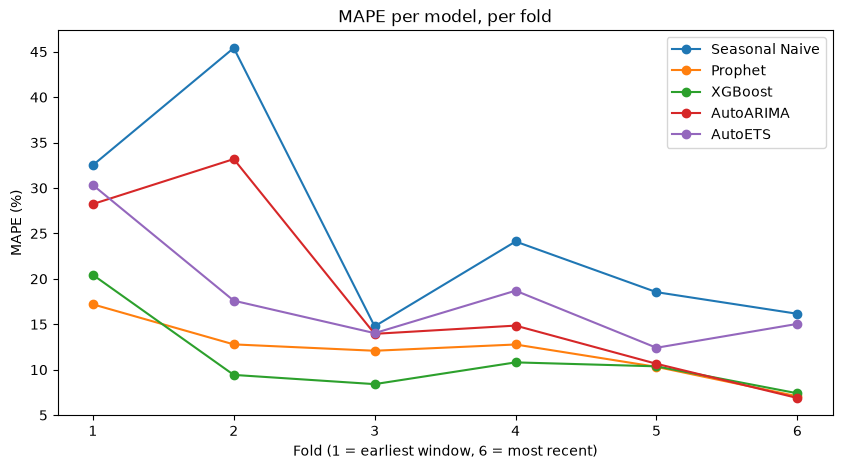

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
for name in model_order:
    sub = per_fold_df[per_fold_df['model'] == name].sort_values('fold')
    ax.plot(sub['fold'], sub['MAPE'], marker='o', label=name)
ax.set_xticks(per_fold_df['fold'].unique())
ax.set_xlabel(f'Fold (1 = earliest window, {N_FOLDS} = most recent)')
ax.set_ylabel('MAPE (%)')
ax.set_title('MAPE per model, per fold')
ax.legend()
plt.show()


**All 6 folds, every model beats the baseline.** In the earlier 4-fold, open-days-only, no-exogenous version of this comparison, AutoETS lost to the baseline every fold, and XGBoost beat it in only 2 of 4 — driven almost entirely by one lucky fold. With full-calendar data and exogenous features, every model now beats seasonal-naive in **all 6 folds**, no exceptions.

**MAPE vs. WAPE: mostly agree, with one surprise.** WAPE was added on a hunch that MAPE might be inflated by near-zero sales days (Christmas Eve/New Year's Eve). The summary table above shows the two agree closely overall — same ranking, similar magnitudes across all five models. But fold 1 (22 Nov 2014 – 2 Jan 2015, spanning the December peak and crash) shows the opposite of the hypothesis: WAPE is *higher* than MAPE there for every model except Prophet. So fold 1's difficulty isn't low-sales days inflating a percentage average — it's models mis-sizing the **magnitude of the December peak itself**, which WAPE weights more heavily (it weights errors by actual sales value, so large-sales days dominate) while MAPE treats every day equally. The original hypothesis wasn't confirmed, but this is exactly the divergence WAPE is there to catch — worth keeping as a permanent second check.

**Winner: XGBoost, with Prophet as a cheaper runner-up.** XGBoost has the lowest mean MAPE/WAPE and ties Prophet for 6-of-6 consistency — not a single-fold fluke. But Prophet's worst fold (17.19 MAPE) beats XGBoost's worst (20.44), and Prophet fits in a mean of 0.6s/fold vs. XGBoost's 3.2s — **roughly 5x cheaper to retrain**. Irrelevant for one store; scaled to all 1,115 stores in a nightly batch (see Next steps), that's minutes vs. tens of minutes of fit time — worth validating at actual multi-store scale rather than assuming this ratio holds exactly.

**Skip AutoARIMA.** Its mean MAPE (17.96) barely beats AutoETS's (18.02), but it takes a mean of **65 seconds to fit** per fold (peaking above 2 minutes in fold 1) against AutoETS's 0.6 seconds — two orders of magnitude slower for essentially the same accuracy. It did post the single best score of any model in any fold (6.88 MAPE / 6.69 WAPE, fold 6) — a reminder that any one fold can favor any model — but it doesn't hold up on average or on cost. (Fit times vary somewhat between runs on this machine — a directional signal, not a precise benchmark.)

**Recommendation:** use **XGBoost** as the default model for this store — it wins on both accuracy and full-fold consistency. Treat **Prophet** as the cost-conscious alternative: nearly as accurate, a tighter worst case, and markedly cheaper to retrain — worth it if nightly compute cost across many stores becomes a constraint. Avoid AutoARIMA; AutoETS is the better `statsforecast` pick if a fast, dependency-light option is ever needed. See the README's Recommendation section for how this plays out as a production decision.